# Business Problem
A global e-commerece company operating across multiple region manages end to end order fulfillment including shipping and delivery, for like sporting goods.The company is facing incosisen delivery nperfomance, where actual shipping deviates from schedule timeslines, leading to late deliveries and unpredictable order profitability.

## Desire Outcomes
The goal is to analyze delivery operation, operation bottolneck, and a build a predictive model to reduce delays, optimize shiping decision and improve overall profitability and efficency.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings 
filterwarnings('ignore')

In [2]:
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")

viridis_colors = cm.viridis(np.linspace(0, 1, 5))

primary_color = viridis_colors[0]
secondary_color = viridis_colors[1]
accent_color = viridis_colors[2]
danger_color = '#800000'
neutral_color = viridis_colors[4]
custom_palette = viridis_colors

In [3]:
df =pd.read_csv("E:\Desktop\Work\Supply chain\Dataco\DataCoSupplyChainDataset.csv", encoding ='latin-1')

In [4]:
df

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class


In [5]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [6]:
#Overview
print("rows, cols:", df.shape)
print('\ncolumns:')
print(df.columns.tolist())
print('\nNum duplicates:', df.duplicated().sum())
print('\nMissing Value (top20):')
print(df.isnull().sum().sort_values(ascending=False).head(20))

rows, cols: (180519, 53)

columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Produc

In [7]:
# Data cleaning
columns_to_drop =['Category Id',
                  'Customer Email',
                  'Customer Id',
                  'Customer Fname',
                  'Customer Lname',
                  'Customer Password', 
                  'Customer Street',
                  'Customer State',
                  'Customer Zipcode',
                  'Customer City',
                  'Market',
                  'Department Id',
                  'Benefit per order',
                  'Latitude', 
                  'Longitude', 
                  'Order Item Cardprod Id',
                  'Order Customer Id',
                  'Order Item Discount',
                  'Order Item Discount Rate',
                  'Order Item Id',
                  'Order Item Product Price',
                  'Order Item Quantity', 
                  'Order Item Total', 
                  'Order City',
                  'Order Id',
                  'Order State',
                  'Order Country',
                  'Order Zipcode',
                  'Product Card Id',
                  'Product Category Id',
                  'Product Description', 
                  'Product Image',
                  'Product Status']

df = df.drop(columns= columns_to_drop)

df = df[df['Delivery Status'] != 'Shipping canceled']

for c in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    df[c] = pd.to_datetime(df[c], errors ='coerce', dayfirst=False)
    
print("rows, cols:", df.shape)
print('\nMissing Value (top5):')
print(df.isnull().sum().sort_values(ascending=False).head(5))

rows, cols: (172765, 20)

Missing Value (top5):
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Sales per customer               0
Delivery Status                  0
dtype: int64


In [8]:
df

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-31 22:56:00,0.29,327.750000,91.250000,Southeast Asia,COMPLETE,Smart watch,327.750000,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-13 12:27:00,-0.80,327.750000,-249.089996,South Asia,PENDING,Smart watch,327.750000,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,2018-01-13 12:06:00,-0.80,327.750000,-247.779999,South Asia,CLOSED,Smart watch,327.750000,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,2018-01-13 11:45:00,0.08,327.750000,22.860001,Oceania,COMPLETE,Smart watch,327.750000,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,2018-01-13 11:24:00,0.45,327.750000,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.750000,2018-01-15 11:24:00,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,399.980011,Shipping on time,0,Fishing,EE. UU.,Home Office,Fan Shop,2016-01-16 03:40:00,0.10,399.980011,40.000000,Eastern Asia,CLOSED,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-20 03:40:00,Standard Class
180515,DEBIT,3,2,395.980011,Late delivery,1,Fishing,EE. UU.,Corporate,Fan Shop,2016-01-16 01:34:00,-1.55,399.980011,-613.770019,Eastern Asia,COMPLETE,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-19 01:34:00,Second Class
180516,TRANSFER,5,4,391.980011,Late delivery,1,Fishing,EE. UU.,Corporate,Fan Shop,2016-01-15 21:00:00,0.36,399.980011,141.110001,Oceania,PENDING,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-20 21:00:00,Standard Class
180517,PAYMENT,3,4,387.980011,Advance shipping,0,Fishing,Puerto Rico,Consumer,Fan Shop,2016-01-15 20:18:00,0.48,399.980011,186.229996,Oceania,PENDING_PAYMENT,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-18 20:18:00,Standard Class


In [9]:
# value counts for categorical columns with low cardianility

for col in df.columns:
    if df[col].nunique() < 10:
        print(f'\n{col}, value couns:')
        print(df[col].value_counts())


Type, value couns:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real), value couns:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Days for shipment (scheduled), value couns:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Delivery Status, value couns:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Late_delivery_risk, value couns:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

Customer Country, value couns:
Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

Customer Segment, value couns:
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

Order Status, value couns:
Order Status
COMPLETE  

In [10]:
# Calculating order processing time and delay
df['Order Processing Time'] = (df['shipping date (DateOrders)'] -df['order date (DateOrders)']).dt.days
df['Delay'] =df['Order Processing Time'] - df['Days for shipment (scheduled)']
df ['Is_Delayed'] = df['Delay'] > 0
df['Order_month'] = df['order date (DateOrders)'].dt.month
df['Order_day'] = df['order date (DateOrders)'].dt.day_name()
df['Order_hour'] = df['order date (DateOrders)'].dt.hour
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,Delay,Order_month,Order_hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991,0.120801,203.828493,22.032360,141.278595,2016-06-16 03:25:14.452927,3.472816,0.539716,6.235511,11.482604
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,119.980003,7.030000,50.000000,2015-09-25 08:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 03:38:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 08:00:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,132.392520,104.355313,139.862956,NaN,1.670187,1.494150,3.405593,6.927276


In [11]:
df['Is_Delayed'].value_counts()

Is_Delayed
True     94523
False    78242
Name: count, dtype: int64

In [12]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Sales per customer', 'Delivery Status', 'Late_delivery_risk',
       'Category Name', 'Customer Country', 'Customer Segment',
       'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio',
       'Sales', 'Order Profit Per Order', 'Order Region', 'Order Status',
       'Product Name', 'Product Price', 'shipping date (DateOrders)',
       'Shipping Mode', 'Order Processing Time', 'Delay', 'Is_Delayed',
       'Order_month', 'Order_day', 'Order_hour'],
      dtype='str')

In [13]:
df['Profitability flag']= np.where(df['Order Profit Per Order'] > 0, 'Profit', np.where(df['Order Profit Per Order'] < 0, 'Loss', 'Break-even'))
df['Profitability flag'].value_counts()

Profitability flag
Profit        139354
Loss           32295
Break-even      1116
Name: count, dtype: int64

In [14]:
df['Profitability flag'].value_counts(normalize = True)

Profitability flag
Profit        0.80661
Loss          0.18693
Break-even    0.00646
Name: proportion, dtype: float64

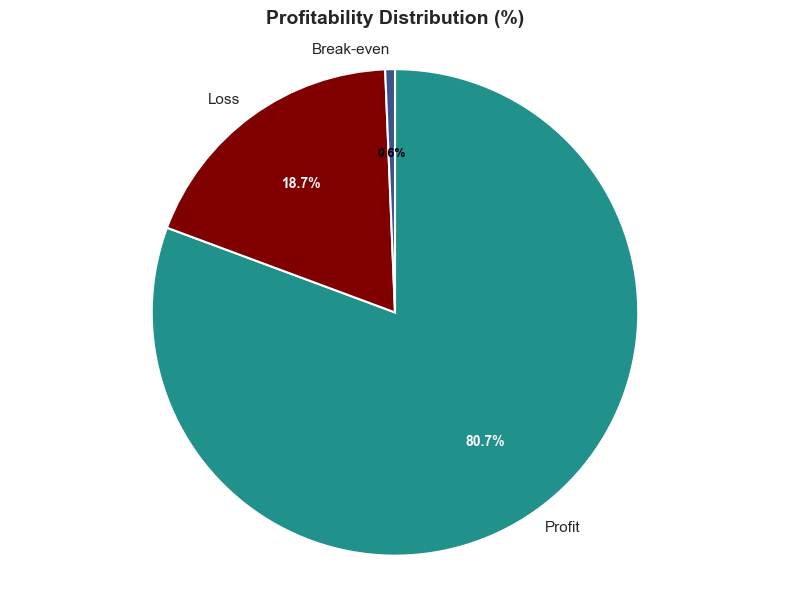

In [15]:

# Visualization of profitability distribution
profit_counts = df['Profitability flag'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax.pie(
    profit_counts,
    labels=profit_counts.index,
    autopct='%1.1f%%',
    colors=[accent_color, danger_color, secondary_color],
    startangle=90,
    counterclock=False,
    pctdistance=0.65,
    labeldistance=1.08,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    textprops={'fontsize': 11}
)

# Improve percentage label readability
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_color('white')
    autotext.set_fontweight('bold')

# Handle the very small Break-even slice
for i, label in enumerate(profit_counts.index):
    if label == 'Break-even':
        autotexts[i].set_color('black')
        autotexts[i].set_fontsize(9)

ax.set_title(
    'Profitability Distribution (%)',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.axis('equal')
plt.tight_layout()
plt.show()


In [17]:
def format_func(value):
    if abs(value) >= 1e6:
        return f'{value / 1e6:.1f}M $'
    elif abs(value) >= 1e3:
        return f'{value / 1e3:.1f}K $'
    else:
        return f'{value:.0f} $'

delayed_df = df[df['Delay'] > 0]
metrics = {}
metrics['Total Orders'] = len(df)
metrics['late Deliveries'] = len(delayed_df)
metrics['90% Delay (days)'] = delayed_df['Delay'].quantile(0.90)
metrics['On time Delivery %'] = (1-float(metrics['late Deliveries']) / metrics['Total Orders']) * 100
metrics['Late Delivery %'] = float(metrics['late Deliveries']) / metrics['Total Orders'] * 100
metrics['Total Profit'] = format_func(df.loc[df['Order Profit Per Order'] > 0, 'Order Profit Per Order'].sum())
metrics['Total Loss due to delays'] = format_func(df.loc[df['Delay'] > 0, 'Order Profit Per Order'].sum())

print('\n----Business KPIs ----\n')
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k}: {v:.2f}")
    else:
        print(f"{k}: {v}")


----Business KPIs ----

Total Orders: 172765
late Deliveries: 94523
90% Delay (days): 3.00
On time Delivery %: 45.29
Late Delivery %: 54.71
Total Profit: 7.5M $
Total Loss due to delays: 2.1M $


In [18]:
# Profitability Vs Delivery Time Analysis
profit_metrics = (
    df.groupby('Delay') ['Order Profit Per Order']
    .agg(
        mean_profit ='mean',
        total_profit ='sum',
        order_count = 'count'
    )
    .reset_index()
)

In [19]:
profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2,23.360134,4.875961e+05,20873
1,-1,21.604769,4.476292e+05,20719
2,0,22.249118,8.154302e+05,36650
3,1,22.333227,1.194895e+06,53503
4,2,21.128491,5.821110e+05,27551
5,3,20.031412,1.356527e+05,6772
6,4,21.368783,1.431067e+05,6697


In [20]:
delay_distribution = (
    df['Delay'].value_counts(normalize=True).sort_index() * 100).reset_index()


In [21]:
delay_distribution

,Delay,proportion
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364



pProfit Merics by Delay Day:


,Delay,mean_profit,total_profit,order_count
0,-2,23.4,487596.1,20873
1,-1,21.6,447629.2,20719
2,0,22.2,815430.2,36650
3,1,22.3,1194894.7,53503
4,2,21.1,582111.0,27551
5,3,20.0,135652.7,6772
6,4,21.4,143106.7,6697



Delay Distribution (%):


,Delay_Days,Percentage
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364


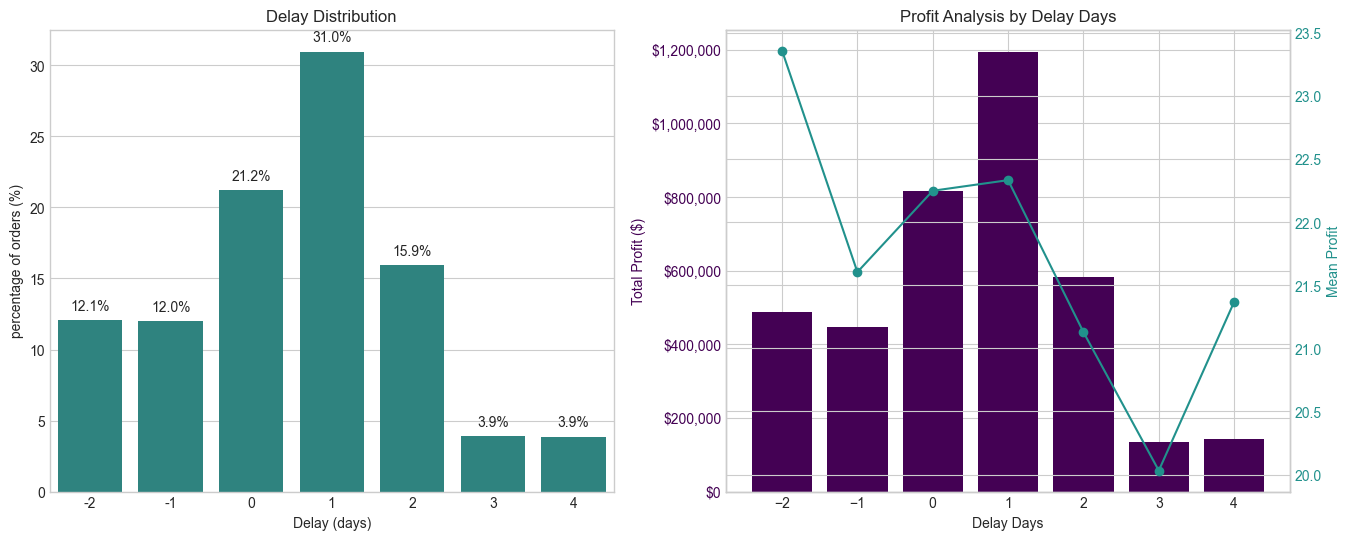

In [22]:
delay_distribution.columns = ['Delay_Days', 'Percentage']

print("\npProfit Merics by Delay Day:")
display(profit_metrics.round(1))

print("\nDelay Distribution (%):")
display(delay_distribution)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,6))

# First subplot: Delay Distribution 
sns.barplot(x='Delay_Days', y='Percentage', data=delay_distribution, color=accent_color, ax=ax1)
ax1.set_title('Delay Distribution')
ax1.set_xlabel('Delay (days)')
ax1.set_ylabel('percentage of orders (%)')

#percentage text on bars
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 0.5, f'{height:.1f}%', ha='center', va='bottom')

#Second subplot: Profit Analysis by Delay Days
ax2.set_title('Profit Analysis by Delay Days')
ax2.set_xlabel('Delay Days')
ax2.set_ylabel("Total Profit ($)", color =primary_color)
ax2.bar(profit_metrics ['Delay'], profit_metrics['total_profit'], color=primary_color, label ='Total Profit')

# Remove scientific notation and display full values
ax2.ticklabel_format(axis='y', style='plain')
ax2.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'${x:,.0f}')
)

ax2.tick_params(axis ='y', labelcolor=primary_color)

ax3 =ax2.twinx()

ax3.set_xlabel("Delay Days")
ax3.set_ylabel("Mean Profit", color=accent_color)
ax3.plot(profit_metrics['Delay'], profit_metrics['mean_profit'], marker='o', label ='Mean Profit', color=accent_color)
ax3.tick_params(axis ='y', labelcolor=accent_color)

        

# Bottelneck finding

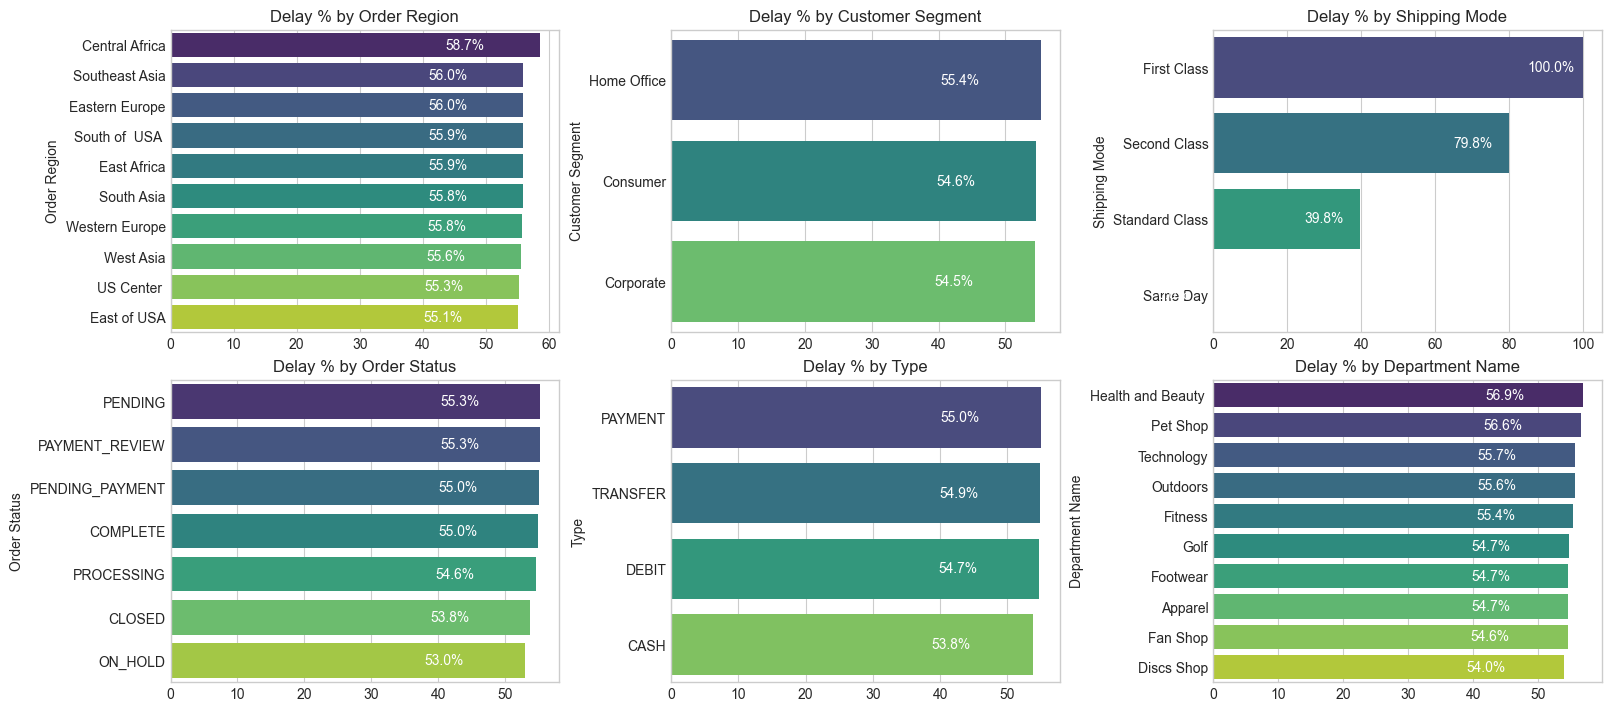

In [23]:
def compute_delay_pct_by_category(category):
    cat_df = df.groupby(category).agg(
        total_orders=('Delay', 'count'),
        late_orders =('Is_Delayed', 'sum')
    ).reset_index()
    cat_df['delay_pct'] = cat_df['late_orders'] / cat_df['total_orders'] * 100
    cat_df = cat_df.sort_values('delay_pct', ascending = False).head(10)
    return cat_df

categories =['Order Region', 'Customer Segment', 'Shipping Mode', 'Order Status', 'Type', 'Department Name']

fig, axes = plt.subplots(2, 3, figsize=(16,7), constrained_layout = True)
axes = axes.flatten()

for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_by_category(category)
    sns.barplot(
        data=cat_df,
        x='delay_pct',
        y=category,
        ax=ax,
        palette='viridis'
    )
    ax.set_title(f'Delay % by {category}')
    ax.set_xlabel('')
    ax.set_ylabel(category)
    for i, row in cat_df.reset_index().iterrows():
        ax.text(row['delay_pct'] -15, i, f"{row['delay_pct']:.1f}%", va='center', fontsize=10, color= 'white')

plt.show()
                

# Root Cause Analysis

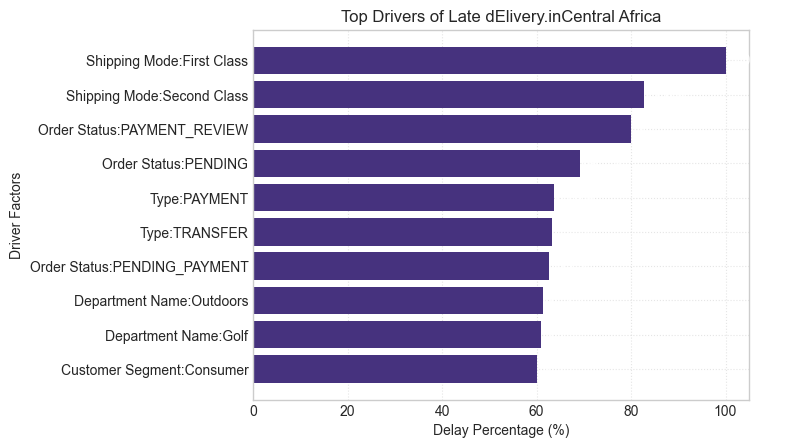

In [24]:
# Top driversof late delivery by region

def top_drivers_for_region(region):
    df_region = df[df['Order Region'] == region].copy()

    drivers = ['Shipping Mode', 'Customer Segment', 'Department Name', 'Type', 'Order Status']

    all_factors =[]
    for factor in drivers:
        temp = (
            df_region.groupby(factor)
            .agg(
                total_orders = ('Delay', 'count'),
                late_orders = ('Is_Delayed', 'sum'),
                avg_delay =('Delay','mean')
            )
            .reset_index()
        )

        temp['delay_pct'] = temp['late_orders'] / temp['total_orders'] * 100
        temp['Driver'] =factor
        temp['Factor_level'] = factor + ":" + temp[factor].astype(str)

        all_factors.append (temp[['Driver', 'Factor_level', 'delay_pct', 'avg_delay', 'total_orders']])

    # Combine all drivers
    find_df = pd.concat(all_factors)

    

    # Top 10 drivers
    top_factors = find_df.sort_values('delay_pct', ascending = False).head(10)
    plt.figure()

    bars =plt.barh(top_factors['Factor_level'], top_factors['delay_pct'])

    plt.xlabel("Delay Percentage (%)")
    plt.ylabel("Driver Factors")
    plt.title(f"Top Drivers of Late dElivery.in{region}")
    plt.grid(True, linestyle=':', alpha =0.5)
    plt.gca().invert_yaxis()
    for bar in bars:
        width = bar.get_width()
        plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.1f}%',
        va='center',
        fontsize=10,
        color='white'
    )
    plt.show()

top_drivers_for_region('Central Africa')
                                      
                

# Time Series Analysis

In [25]:
# Convert order date to datetime
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'],
    errors='coerce'
)

# Extract time features
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.dayofweek
df['order_hour'] = df['order date (DateOrders)'].dt.hour

In [26]:
# Delay % by Month, day of the week, Hour.

delay_by_month = (
    df.groupby('order_month')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100

delay_by_day = (
    df.groupby('order_day')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100

delay_by_hour = (
    df.groupby('order_hour')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100





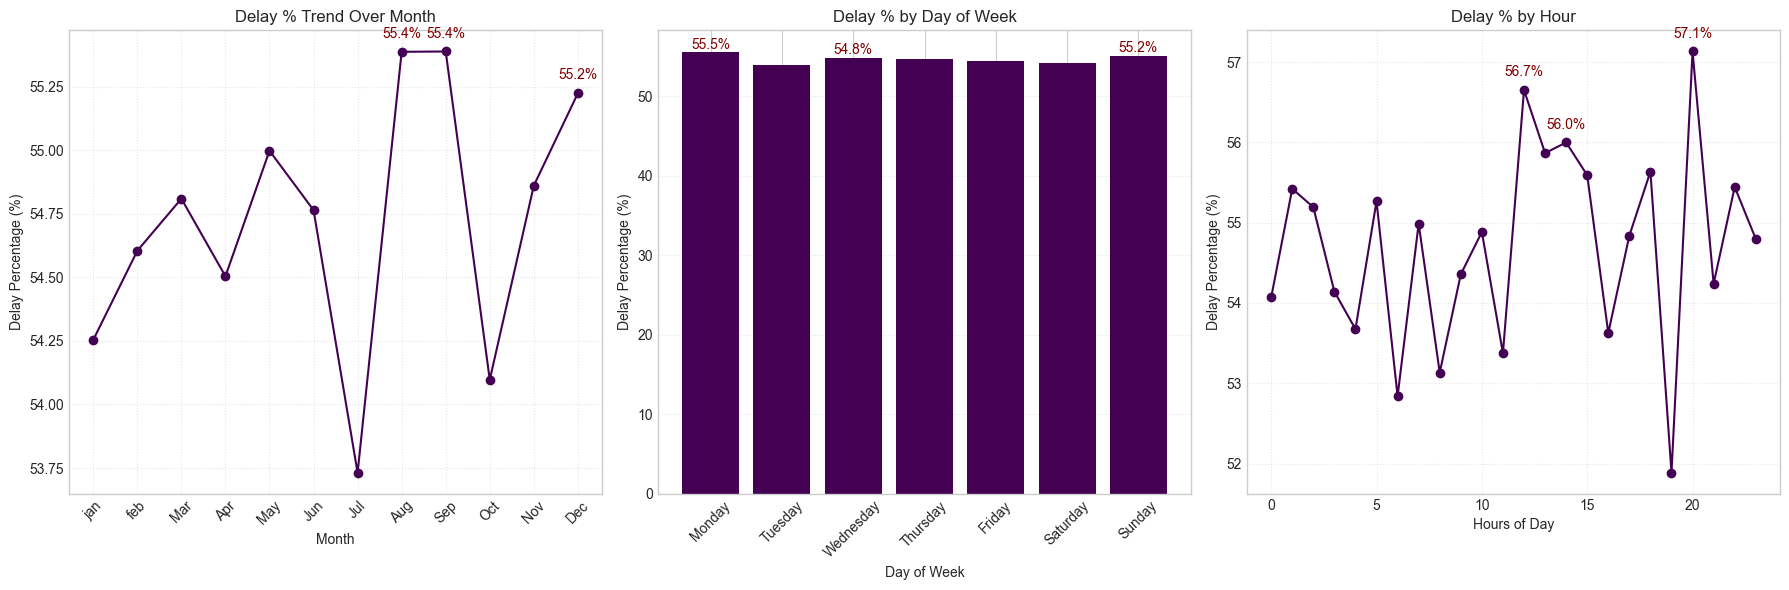

In [27]:
fig, (ax1, ax2, ax3) =plt.subplots(1, 3, figsize=(18, 6))

#Subplot1: Delay % Trend Over Month
ax1.plot(delay_by_month['order_month'], delay_by_month['delay_pct'], marker='o', color=primary_color)
ax1.set_xticks(range(1,13))
ax1.set_xticklabels(['jan', 'feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug','Sep', 'Oct', 'Nov', 'Dec'], rotation = 45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month")
ax1.grid(True, linestyle = ':',alpha=0.5)

# Annotate top 3 highest
top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['order_month'], row['delay_pct']),
                 textcoords ="offset points", xytext=(0,10), ha='center', fontsize=10, color=danger_color)


# Subplot 2: Delay % by Day of Week

# Convert numeric weekdays (0=Monday, 6=Sunday) to names
day_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

delay_by_day = (
    df.groupby('order_day')['Is_Delayed']
    .mean()
    .mul(100)
    .reset_index(name='delay_pct')
)

delay_by_day['order_day'] = delay_by_day['order_day'].map(day_names)

day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

delay_by_day['order_day'] = pd.Categorical(
    delay_by_day['order_day'],
    categories=day_order,
    ordered=True
)

delay_by_day = delay_by_day.sort_values('order_day')

ax2.bar(
    delay_by_day['order_day'],
    delay_by_day['delay_pct'],
    color=primary_color
)

ax2.set_xlabel('Day of Week')
ax2.set_ylabel('Delay Percentage (%)')
ax2.set_title('Delay % by Day of Week')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', linestyle=':', alpha=0.5)

# Annotate top 3 highest bars
top3_day = delay_by_day.nlargest(3, 'delay_pct')

for _, row in top3_day.iterrows():
    height = row['delay_pct']

    ax2.text(
        row['order_day'],
        height + 0.5,
        f'{height:.1f}%',
        ha='center',
        fontsize=10,
        color=danger_color
    )

# Subplot 3:Dealy %by Hour
ax3.plot(delay_by_hour['order_hour'], delay_by_hour['delay_pct'], marker='o', color=primary_color)
ax3.set_xlabel("Hours of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour")
ax3.grid(True, linestyle = ':', alpha=0.5)

# Annotate top 3 highest
top3_hour= delay_by_hour.nlargest(3, 'delay_pct')
for _, row in top3_hour.iterrows():
    ax3.annotate(f"{row['delay_pct']:.1f}%", (row['order_hour'], row['delay_pct']),
                 textcoords ="offset points", xytext=(0,10), ha='center', fontsize=10, color=danger_color)
plt.tight_layout()
plt.show()

# Machine Larning Modeling

In [28]:
%pip install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

In [30]:
x = df[['Type', 'Days for shipment (scheduled)', 'Category Name','Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode', 'order_month', 'order_hour']]
y = df['Late_delivery_risk']

In [31]:
cat_cols = x.select_dtypes(include=['object', 'category']).columns.tolist()
print('Categorical columns:', cat_cols)

# Frequency encoding (low_dimesnional and robust for high_cardianility)
for col in cat_cols:
    freq = x[col].value_counts(normalize = True)
    x[f'{col}_freq'] = x[col].map(freq)

# Keep numeric columns + new encoded features, drop original sring categories
x_encoded = x.drop(columns = cat_cols)
print('Shape after freq+target encoding:', x_encoded.shape)

#use encoded features of modeling

x=x_encoded

# train/test spirit after encoding
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.2, random_state = 42, stratify=y
)

    

Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']
Shape after freq+target encoding: (172765, 9)


In [32]:
# Balancing the training data using SMOTE
print("Before balancing (train):", Counter(y_train))

smote = SMOTE(random_state=42)
x_train_bal, y_train_bal = smote.fit_resample(x_train, y_train)

print("After balancing (train):",Counter(y_train_bal))

Before balancing (train): Counter({1: 79182, 0: 59030})
After balancing (train): Counter({0: 79182, 1: 79182})


In [33]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred),2))
    print("Recall:", round(recall_score(y_true, y_pred),2))
    print("\nClassification Report:\n", classification_report(y_true, y_pred))

In [34]:
# Fit the Random Forest Model on blanced data
rf_model_balanced = RandomForestClassifier(random_state = 42)
rf_model_balanced.fit(x_train_bal, y_train_bal)

y_pred_rf_balanced = rf_model_balanced.predict(x_test)
evaluate_model(y_test, y_pred_rf_balanced, "Random Forset Classifier")


--- Random Forset Classifier ---
Accuracy: 0.74
Recall: 0.75

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.73      0.70     14758
           1       0.79      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553

